# Module 4 (step 3) – Grid search, advanced models and ensembles

Follow-up of `04_baseline.ipynb`, and application of **lab 6, part II** to the project:
1. **Grid search** on the baseline (logistic regression) to find its best configuration.
2. Advanced models: **random forest**, **gradient boosting** and an **MLP** (out-of-course model).
3. **Ensembles**: voting (average of probabilities), bagging and stacking.
4. **Uncertainty**: bootstrap confidence intervals and paired comparison with the baseline.
5. Figures and comparison table (performance, time, interpretability).
6. Impact of the hours-played leak (AI_AUDIT, Flaw 2).
7. Final evaluation on the test set (disabled until the final model is chosen).

**Lab 6 traps, adapted to our project**

| Lab 6 trap | What we do here |
|---|---|
| random `cv=2` | `PredefinedSplit`: tuning on **our time-based validation set**, never on random folds |
| `scoring="accuracy"` | `scoring="average_precision"` (PR-AUC): imbalanced classes (~15% successes) |
| scaling outside the pipeline | imputation, scaling and encoding **inside** the pipeline, fitted on train |
| `refit=True` | `refit=False`: with `PredefinedSplit`, `refit=True` would retrain on train + validation and we could no longer evaluate on validation |
| evaluating on the test set to choose | the test set is used **only once**, at the end |
| missing `random_state` | `random_state=SEED` everywhere |

In [1]:
import sys, time
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, BaggingClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit, KFold
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)
from config import *

# QUICK = True: fast smoke test (~3 min, measured) to check that everything runs: T in {0, 30}, 2 configurations per
# search, small bagging and stacking, 100 bootstrap samples, no C curve and no hours-leak section. Results go to report/figures/quick/
# and are NOT written to the result tables. Use QUICK = False for the real results (~20 min).
QUICK = False

FIG_DIR = ROOT / "report" / "figures" / ("quick" if QUICK else "")
FIG_DIR.mkdir(parents=True, exist_ok=True)

target = pd.read_parquet(PROC_DIR / "target.parquet")
static = pd.read_parquet(PROC_DIR / "features_static.parquet")
print("Games:", len(target), "| Static features:", static.shape)

Games: 10000 | Static features: (10000, 217)


## 0. Data and pipeline (same as notebook 04)

We reuse exactly `make_dataset` and the preprocessing of notebook 04, so that the baseline is comparable.
Games are **sorted by release date** (used by stacking, section 3).

In [2]:
NUM_COLS = ["log_price", "required_age", "n_languages", "desc_length", "n_reviews", "pos_ratio"]
CAT_COLS = ["release_month", "release_weekday"]
T_LIST = [0, 30] if QUICK else T_VALUES  # [0, 7, 30, 90]
N_ITER = 2 if QUICK else 8                # configurations per random search

def make_dataset(T):
    df = target[["app_id", "release_date", "split", "success"]].merge(static, on="app_id")
    if T > 0:
        df = df.merge(pd.read_parquet(PROC_DIR / f"features_T{T}.parquet"), on="app_id")
        df["n_reviews"] = np.log1p(df["n_reviews"])
    df["desc_length"] = np.log1p(df["desc_length"])
    return df.sort_values(["release_date", "app_id"]).reset_index(drop=True)

def make_preprocess(df):
    num = [c for c in NUM_COLS if c in df.columns]
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        remainder="passthrough")

DATA = {}
for T in T_LIST:
    df = make_dataset(T)
    tr, va = df[df["split"] == "train"], df[df["split"] == "val"]
    X_cols = [c for c in df.columns if c not in ["app_id", "release_date", "split", "success"]]
    DATA[T] = dict(df=df, Xtr=tr[X_cols], ytr=tr["success"], Xva=va[X_cols], yva=va["success"])
    assert tr["release_date"].max() < va["release_date"].min()   # no shared release day

print({T: DATA[T]["Xtr"].shape for T in T_LIST})
print("Success rate on validation (PR-AUC of a random model):", round(DATA[0]["yva"].mean(), 3))

{0: (7007, 216), 7: (7007, 219), 30: (7007, 219), 90: (7007, 219)}
Success rate on validation (PR-AUC of a random model): 0.157


In [3]:
def predefined_split(d):
    # train = -1 (never in validation), val = 0 (the only validation fold)
    X = pd.concat([d["Xtr"], d["Xva"]])
    y = pd.concat([d["ytr"], d["yva"]])
    fold = np.r_[np.full(len(d["Xtr"]), -1), np.zeros(len(d["Xva"]))]
    return X, y, PredefinedSplit(fold)

def evaluate(model, d, name, T, fit_time=np.nan):
    t0 = time.perf_counter()
    p = model.predict_proba(d["Xva"])[:, 1]
    pred_time = time.perf_counter() - t0
    yhat = (p >= 0.5).astype(int)
    return dict(model=name, T=T, **{"PR-AUC": average_precision_score(d["yva"], p),
                "ROC-AUC": roc_auc_score(d["yva"], p),
                "F1": f1_score(d["yva"], yhat, zero_division=0),
                "precision": precision_score(d["yva"], yhat, zero_division=0),
                "recall": recall_score(d["yva"], yhat, zero_division=0),
                "fit_s": fit_time, "predict_s": pred_time}), p

def fit_timed(model, d):
    t0 = time.perf_counter()
    model.fit(d["Xtr"], d["ytr"])
    return model, time.perf_counter() - t0

ROWS, PROBA, MODELS = [], {}, {}

def record(model, d, name, T, fit_time):
    row, p = evaluate(model, d, name, T, fit_time)
    ROWS.append(row); PROBA[(name, T)] = p; MODELS[(name, T)] = model
    return row

## 1. Baseline of notebook 04, then grid search on the logistic regression

Baseline of notebook 04: `LogisticRegression(max_iter=1000, class_weight="balanced")`, with `C = 1` and the
default L2 penalty. We search:
- `C`: regularisation strength (small `C` = smaller coefficients = simpler model, less variance);
- `l1_ratio`: 0 = L2 penalty (ridge), 1 = L1 penalty (lasso, sets coefficients to 0: feature selection);
- `class_weight`: `None` or `"balanced"`.

In scikit-learn 1.9 the `penalty` parameter is deprecated: we use `l1_ratio` with the `saga` solver
(the only solver that accepts both L1 and L2).

In [4]:
LR_GRID = {"logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3],
           "logisticregression__l1_ratio": [0, 1],
           "logisticregression__class_weight": [None, "balanced"]}
if QUICK:  # 2 configurations only
    LR_GRID = {"logisticregression__C": [0.1, 1], "logisticregression__l1_ratio": [1],
               "logisticregression__class_weight": [None]}
BEST_LR = {}

for T in T_LIST:
    d = DATA[T]
    base = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    base, ft = fit_timed(base, d)
    record(base, d, "LogReg (baseline 04)", T, ft)

    pipe = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(solver="saga", max_iter=3000, random_state=SEED))
    X, y, ps = predefined_split(d)
    gs = GridSearchCV(pipe, LR_GRID, scoring="average_precision", cv=ps, refit=False, n_jobs=-1)
    gs.fit(X, y)
    BEST_LR[T] = gs.best_params_
    best, ft = fit_timed(clone(pipe).set_params(**gs.best_params_), d)   # refit on train only
    record(best, d, "LogReg (grid search)", T, ft)
    print(f"T={T:>2} best parameters: {gs.best_params_} | validation PR-AUC = {gs.best_score_:.3f}")

T= 0 best parameters: {'logisticregression__C': 0.3, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | validation PR-AUC = 0.456


T= 7 best parameters: {'logisticregression__C': 0.1, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | validation PR-AUC = 0.821


T=30 best parameters: {'logisticregression__C': 0.1, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | validation PR-AUC = 0.862


T=90 best parameters: {'logisticregression__C': 0.3, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | validation PR-AUC = 0.885


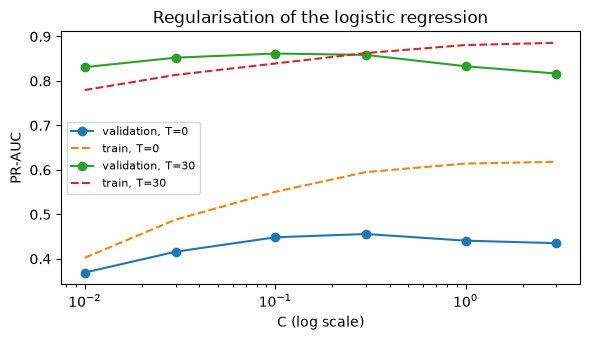

In [5]:
# Effect of C on the validation PR-AUC (bias / variance), at T = 0 and T = 30
fig, ax = plt.subplots(figsize=(6, 3.5))
for T in ([] if QUICK else [0, 30]):   # skipped in QUICK mode
    d = DATA[T]; X, y, ps = predefined_split(d)
    pipe = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(solver="saga", max_iter=3000, random_state=SEED,
                                            l1_ratio=BEST_LR[T]["logisticregression__l1_ratio"],
                                            class_weight=BEST_LR[T]["logisticregression__class_weight"]))
    gs = GridSearchCV(pipe, {"logisticregression__C": LR_GRID["logisticregression__C"]},
                      scoring="average_precision", cv=ps, refit=False, return_train_score=True, n_jobs=-1).fit(X, y)
    r = pd.DataFrame(gs.cv_results_)
    ax.plot(r["param_logisticregression__C"], r["mean_test_score"], marker="o", label=f"validation, T={T}")
    ax.plot(r["param_logisticregression__C"], r["mean_train_score"], ls="--", label=f"train, T={T}")
ax.set(xscale="log", xlabel="C (log scale)", ylabel="PR-AUC", title="Regularisation of the logistic regression")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "logreg_C.png", dpi=150); plt.show()

**Reading:** on the left (small `C`) the model is too constrained: train and validation scores are both low
(**bias**). On the right (large `C`) the train score keeps increasing while the validation score stalls or
drops: the model starts to learn the noise of the training set (**variance**). The best `C` is where the
validation score peaks.

## 2. Advanced models: random forest, gradient boosting, MLP

Random search (`RandomizedSearchCV`, 8 configurations per model and per T, limited budget) rather than a full
grid: for the same budget it explores more distinct values of each parameter (Bergstra and Bengio, 2012).

- **Random forest**: many deep trees trained on bootstrap samples (= *bagging* of trees), with a random subset
  of features at each split. Averaging reduces the variance.
- **HistGradientBoosting**: small trees added one by one, each one correcting the errors of the previous ones
  (reduces the bias).
- **MLP** (*multilayer perceptron*, out-of-course model): a neural network with one or two hidden layers and
  `early_stopping` to limit overfitting.

The random forest uses one core (`n_jobs=1`) because the search itself already runs in parallel: using all
cores at both levels saturated the CPU (AI_AUDIT).

In [6]:
SEARCH = {
    "Random forest": (RandomForestClassifier(random_state=SEED, n_jobs=1), {
        "randomforestclassifier__n_estimators": [200, 400],
        "randomforestclassifier__max_depth": [None, 8, 16, 32],
        "randomforestclassifier__min_samples_leaf": [1, 3, 10, 30],
        "randomforestclassifier__max_features": ["sqrt", 0.2, 0.4],
        "randomforestclassifier__class_weight": [None, "balanced_subsample"]}),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=SEED), {
        "histgradientboostingclassifier__learning_rate": [0.03, 0.05, 0.1],
        "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63],
        "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
        "histgradientboostingclassifier__l2_regularization": [0, 0.1, 1],
        "histgradientboostingclassifier__max_iter": [200, 400],
        "histgradientboostingclassifier__class_weight": [None, "balanced"]}),
    "MLP": (MLPClassifier(early_stopping=True, max_iter=300, random_state=SEED), {
        "mlpclassifier__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64)],
        "mlpclassifier__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1],
        "mlpclassifier__learning_rate_init": [1e-3, 3e-3]}),
}
BEST_PARAMS = {}

for name, (clf, grid) in SEARCH.items():
    for T in T_LIST:
        d = DATA[T]
        pipe = make_pipeline(make_preprocess(d["df"]), clf)
        X, y, ps = predefined_split(d)
        rs = RandomizedSearchCV(pipe, grid, n_iter=N_ITER, scoring="average_precision", cv=ps,
                                refit=False, random_state=SEED, n_jobs=-1).fit(X, y)
        BEST_PARAMS[(name, T)] = rs.best_params_
        best, ft = fit_timed(clone(pipe).set_params(**rs.best_params_), d)
        row = record(best, d, name, T, ft)
        print(f"{name:<18} T={T:>2} validation PR-AUC = {row['PR-AUC']:.3f}  {rs.best_params_}")

Random forest      T= 0 validation PR-AUC = 0.489  {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__max_depth': 32, 'randomforestclassifier__class_weight': None}


Random forest      T= 7 validation PR-AUC = 0.866  {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 3, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': None}


Random forest      T=30 validation PR-AUC = 0.910  {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': 8, 'randomforestclassifier__class_weight': None}


Random forest      T=90 validation PR-AUC = 0.944  {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': 8, 'randomforestclassifier__class_weight': None}


Gradient boosting  T= 0 validation PR-AUC = 0.486  {'histgradientboostingclassifier__min_samples_leaf': 20, 'histgradientboostingclassifier__max_leaf_nodes': 63, 'histgradientboostingclassifier__max_iter': 200, 'histgradientboostingclassifier__learning_rate': 0.05, 'histgradientboostingclassifier__l2_regularization': 1, 'histgradientboostingclassifier__class_weight': None}


Gradient boosting  T= 7 validation PR-AUC = 0.871  {'histgradientboostingclassifier__min_samples_leaf': 20, 'histgradientboostingclassifier__max_leaf_nodes': 15, 'histgradientboostingclassifier__max_iter': 200, 'histgradientboostingclassifier__learning_rate': 0.03, 'histgradientboostingclassifier__l2_regularization': 1, 'histgradientboostingclassifier__class_weight': None}


... (2 outputs left out)

MLP                T= 0 validation PR-AUC = 0.445  {'mlpclassifier__learning_rate_init': 0.003, 'mlpclassifier__hidden_layer_sizes': (64, 32), 'mlpclassifier__alpha': 0.001}


MLP                T= 7 validation PR-AUC = 0.845  {'mlpclassifier__learning_rate_init': 0.003, 'mlpclassifier__hidden_layer_sizes': (128,), 'mlpclassifier__alpha': 1}


MLP                T=30 validation PR-AUC = 0.892  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (128, 64), 'mlpclassifier__alpha': 1}


MLP                T=90 validation PR-AUC = 0.915  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (128, 64), 'mlpclassifier__alpha': 1}


**About the MLP.** On tabular data (many 0/1 features, few rows), neural networks usually do worse than
tree-based models: see Grinsztajn, Oyallon and Varoquaux (2022), *Why do tree-based models still outperform
deep learning on typical tabular data?*, NeurIPS 2022 (Datasets and Benchmarks), and Shwartz-Ziv and Armon
(2022), *Tabular data: Deep learning is not all you need*, Information Fusion 81. We therefore use it as an
out-of-course model **to compare**, not as the favourite.

## 3. Ensembles: voting, bagging, stacking

- **Soft voting**: average of the probabilities of the tuned logistic regression, random forest and gradient
  boosting. Useful if the models make mistakes on different games.
- **Bagging of the logistic regression**: 25-50 logistic regressions trained on bootstrap samples. The logistic
  regression has little variance, so we expect a small gain (unlike trees, hence the random forest). We tune
  `n_estimators` and `max_samples` as in lab 6. The preprocessing stays **before** the bagging step:
  `BaggingClassifier` converts X to a numpy array and loses the column names needed by the
  `ColumnTransformer` (AI_AUDIT).
- **Stacking**: a meta-model (logistic regression) learns how to combine the probabilities of the three models.
  It is trained on *out-of-fold* predictions of the training set (`KFold(5)` **without shuffling**, on games
  sorted by date: each fold is a continuous period, which limits mixing past and future).

In [7]:
def tuned(name, T):
    return MODELS[(name, T)]

for T in T_LIST:
    d = DATA[T]
    members = [("lr", clone(tuned("LogReg (grid search)", T))),
               ("rf", clone(tuned("Random forest", T))),
               ("gb", clone(tuned("Gradient boosting", T)))]

    vote, ft = fit_timed(VotingClassifier(members, voting="soft", n_jobs=-1), d)
    record(vote, d, "Voting (LR+RF+GB)", T, ft)

    X, y, ps = predefined_split(d)
    lr_best = tuned("LogReg (grid search)", T)[-1]
    bag = make_pipeline(make_preprocess(d["df"]),
                        BaggingClassifier(clone(lr_best), random_state=SEED, n_jobs=-1))
    gs = GridSearchCV(bag, {"baggingclassifier__n_estimators": [10] if QUICK else [25, 50],
                            "baggingclassifier__max_samples": [1.0] if QUICK else [0.5, 1.0]},
                      scoring="average_precision", cv=ps, refit=False).fit(X, y)
    bag, ft = fit_timed(bag.set_params(**gs.best_params_), d)
    record(bag, d, "Bagging (LogReg)", T, ft)

    stack = StackingClassifier(members, final_estimator=LogisticRegression(max_iter=1000),
                               cv=KFold(2 if QUICK else 5, shuffle=False), stack_method="predict_proba", n_jobs=-1)
    stack, ft = fit_timed(stack, d)
    record(stack, d, "Stacking", T, ft)
    print(f"T={T:>2} ensembles trained (bagging: {gs.best_params_})")

results = pd.DataFrame(ROWS)
results.pivot(index="model", columns="T", values="PR-AUC").round(3).sort_values(30, ascending=False)

T= 0 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T= 7 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T=30 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 50})


T=90 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T,0,7,30,90
model,,,,
Gradient boosting,0.486,0.871,0.915,0.941
Stacking,0.501,0.874,0.915,0.946
Voting (LR+RF+GB),0.493,0.873,0.914,0.943
Random forest,0.489,0.866,0.910,0.944
MLP,0.445,0.845,0.892,0.915
Bagging (LogReg),0.451,0.822,0.862,0.884
LogReg (grid search),0.456,0.821,0.862,0.885
LogReg (baseline 04),0.407,0.743,0.810,0.850


## 4. Uncertainty: confidence intervals and comparison with the baseline

The validation set contains only 1,499 games, about 235 of them successes: a 0.01 difference in PR-AUC can be
noise. We resample the validation games 1,000 times (bootstrap):
- **95% CI** of the PR-AUC of each model;
- **paired comparison** with the baseline of notebook 04: both models are evaluated **on the same resampled
  games**, which removes the common variability. If the interval of the difference contains 0, the gain is not
  significant.

Assumption: games are independent. This is only approximate (same publisher, same month), so the intervals
are rather optimistic.

In [8]:
N_BOOT = 100 if QUICK else 1000
y_val = DATA[0]["yva"].to_numpy()          # the same validation games for every T
rng = np.random.default_rng(SEED)
BOOT_IDX = [i for i in (rng.integers(0, len(y_val), len(y_val)) for _ in range(N_BOOT)) if y_val[i].any()]

def boot_scores(p):
    return np.array([average_precision_score(y_val[i], p[i]) for i in BOOT_IDX])

for T in T_LIST:
    assert (DATA[T]["yva"].to_numpy() == y_val).all()

BOOT = {key: boot_scores(p) for key, p in PROBA.items()}
results["CI_low"] = [np.percentile(BOOT[(m, T)], 2.5) for m, T in zip(results["model"], results["T"])]
results["CI_high"] = [np.percentile(BOOT[(m, T)], 97.5) for m, T in zip(results["model"], results["T"])]

diff = []
for (m, T), s in BOOT.items():
    if m == "LogReg (baseline 04)":
        continue
    delta = s - BOOT[("LogReg (baseline 04)", T)]
    diff.append(dict(model=m, T=T, gain=delta.mean(), gain_low=np.percentile(delta, 2.5),
                     gain_high=np.percentile(delta, 97.5), significant=np.percentile(delta, 2.5) > 0))
diff = pd.DataFrame(diff)
diff.pivot(index="model", columns="T", values="gain").round(3)

T,0,7,30,90
model,,,,
Bagging (LogReg),0.045,0.079,0.052,0.034
Gradient boosting,0.078,0.128,0.105,0.091
LogReg (grid search),0.049,0.078,0.052,0.036
MLP,0.037,0.101,0.081,0.065
Random forest,0.082,0.122,0.100,0.095
Stacking,0.092,0.130,0.105,0.096
Voting (LR+RF+GB),0.086,0.129,0.105,0.093


In [9]:
print("PR-AUC gain over the baseline of notebook 04, with 95% CI (paired bootstrap):")
diff.assign(CI=lambda x: "[" + x["gain_low"].round(3).astype(str) + ", " + x["gain_high"].round(3).astype(str) + "]")\
    .pivot(index="model", columns="T", values="CI")

PR-AUC gain over the baseline of notebook 04, with 95% CI (paired bootstrap):


T,0,7,30,90
model,,,,
Bagging (LogReg),"[0.02, 0.069]","[0.054, 0.105]","[0.033, 0.074]","[0.021, 0.048]"
Gradient boosting,"[0.032, 0.123]","[0.091, 0.168]","[0.073, 0.143]","[0.06, 0.127]"
LogReg (grid search),"[0.022, 0.075]","[0.052, 0.106]","[0.032, 0.074]","[0.021, 0.051]"
MLP,"[0.002, 0.073]","[0.074, 0.132]","[0.054, 0.11]","[0.039, 0.093]"
Random forest,"[0.028, 0.135]","[0.084, 0.163]","[0.069, 0.138]","[0.063, 0.129]"
Stacking,"[0.052, 0.134]","[0.096, 0.168]","[0.076, 0.141]","[0.068, 0.129]"
Voting (LR+RF+GB),"[0.049, 0.123]","[0.096, 0.168]","[0.076, 0.139]","[0.066, 0.126]"


## 5. Figures and comparison table

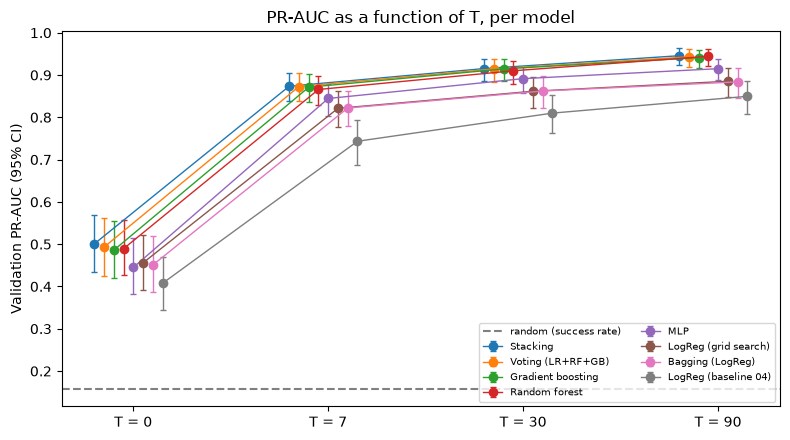

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = results.groupby("model")["PR-AUC"].mean().sort_values(ascending=False).index
for k, m in enumerate(order):
    r = results[results["model"] == m].sort_values("T")
    x = np.arange(len(T_LIST)) + (k - len(order) / 2) * 0.05
    ax.errorbar(x, r["PR-AUC"], yerr=[r["PR-AUC"] - r["CI_low"], r["CI_high"] - r["PR-AUC"]],
                marker="o", capsize=2, lw=1, label=m)
ax.axhline(y_val.mean(), color="gray", ls="--", label="random (success rate)")
ax.set_xticks(range(len(T_LIST)), [f"T = {T}" for T in T_LIST])
ax.set(ylabel="Validation PR-AUC (95% CI)", title="PR-AUC as a function of T, per model")
ax.legend(fontsize=7, ncol=2, loc="lower right"); plt.tight_layout()
plt.savefig(FIG_DIR / "prauc_vs_T_models.png", dpi=150); plt.show()

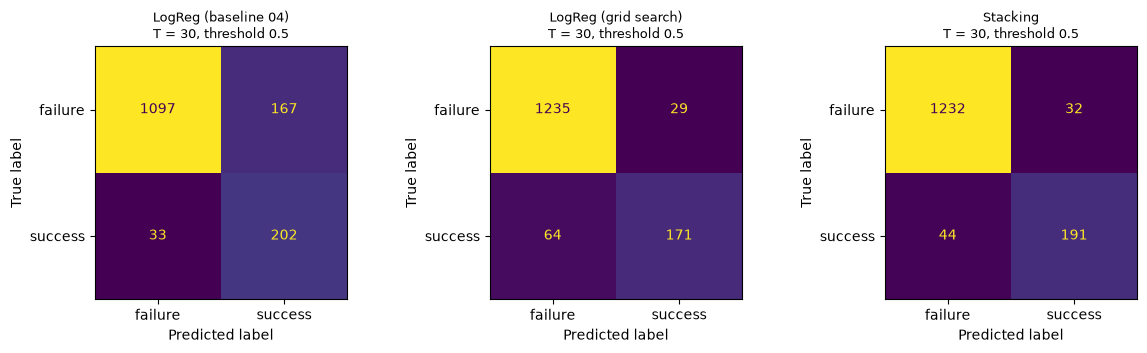

In [11]:
best_T30 = results[results["T"] == 30].sort_values("PR-AUC", ascending=False)["model"].iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, m in zip(axes, ["LogReg (baseline 04)", "LogReg (grid search)", best_T30]):
    p = PROBA[(m, 30)]
    ConfusionMatrixDisplay.from_predictions(y_val, (p >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=["failure", "success"])
    ax.set_title(f"{m}\nT = 30, threshold 0.5", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_T30.png", dpi=150); plt.show()

In [12]:
INTERPRETABILITY = {
    "LogReg (baseline 04)": "high (coefficients)", "LogReg (grid search)": "high (coefficients)",
    "Bagging (LogReg)": "medium (average of 25-50 models)", "Random forest": "low (feature importances only)",
    "Gradient boosting": "low (feature importances only)", "MLP": "very low (black box)",
    "Voting (LR+RF+GB)": "low", "Stacking": "low"}
table = results[results["T"] == 30][["model", "PR-AUC", "CI_low", "CI_high", "ROC-AUC", "F1", "fit_s", "predict_s"]].copy()
table["interpretability"] = table["model"].map(INTERPRETABILITY)
table = table.sort_values("PR-AUC", ascending=False).round(3)
table

,model,PR-AUC,CI_low,CI_high,ROC-AUC,F1,fit_s,predict_s,interpretability
28,Stacking,0.915,0.885,0.938,0.973,0.834,17.596,0.109,low
14,Gradient boosting,0.915,0.886,0.938,0.974,0.835,2.423,0.056,low (feature importances only)
26,Voting (LR+RF+GB),0.914,0.885,0.938,0.972,0.835,6.522,0.109,low
10,Random forest,0.910,0.880,0.934,0.973,0.838,5.923,0.068,low (feature importances only)
18,MLP,0.892,0.858,0.919,0.967,0.806,1.806,0.027,very low (black box)
27,Bagging (LogReg),0.862,0.823,0.897,0.957,0.780,59.188,0.237,medium (average of 25-50 models)
5,LogReg (grid search),0.862,0.823,0.896,0.956,0.786,0.995,0.020,high (coefficients)
4,LogReg (baseline 04),0.810,0.763,0.852,0.943,0.669,0.164,0.017,high (coefficients)


In [13]:
if QUICK:
    print("QUICK mode: result tables not written (figures in report/figures/quick/)")
else:
    results.round(4).to_csv(ROOT / "report" / "results_models.csv", index=False)
    diff.round(4).to_csv(ROOT / "report" / "results_models_vs_baseline.csv", index=False)
    print("written: report/results_models.csv, report/results_models_vs_baseline.csv, report/figures/*.png")

written: report/results_models.csv, report/results_models_vs_baseline.csv, report/figures/*.png


## 6. Impact of the hours-played leak (AI_AUDIT, Flaw 2)

Module 3 removed `hours_mean` and `hours_median` from the early signals: hours are read **at collection
time**, not at review time (13.6% of the first-month reviews have more hours than the time elapsed since
release). The impact on the model was missing. We recompute these two features at T = 30 from
`data/raw/recommendations.csv`, for the same games and the same window `0 <= days < 30`, and compare the
baseline of notebook 04 with and without them.

In [14]:
raw = RAW_DIR / "recommendations.csv"
if QUICK:
    print("QUICK mode: section skipped (it reads the 2 GB review file)")
elif raw.exists():
    rel = target.set_index("app_id")["release_date"]
    rev = pd.read_csv(raw, usecols=["app_id", "date", "hours"], engine="pyarrow")
    rev = rev[rev["app_id"].isin(rel.index)]
    rev["days"] = (pd.to_datetime(rev["date"]) - rev["app_id"].map(rel)).dt.days
    hours = (rev[(rev["days"] >= 0) & (rev["days"] < 30)]
             .groupby("app_id")["hours"].agg(hours_mean="mean", hours_median="median"))

    d = DATA[30]
    with_h = dict(d)  # same games and same target, only the two hours columns are added
    with_h["Xtr"] = d["Xtr"].assign(**hours.reindex(d["df"].loc[d["Xtr"].index, "app_id"]).set_index(d["Xtr"].index))
    with_h["Xva"] = d["Xva"].assign(**hours.reindex(d["df"].loc[d["Xva"].index, "app_id"]).set_index(d["Xva"].index))

    NUM_H = NUM_COLS + ["hours_mean", "hours_median"]
    pre_h = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_H),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS), remainder="passthrough")
    m_h = make_pipeline(pre_h, LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    m_h.fit(with_h["Xtr"], with_h["ytr"])
    p_h = m_h.predict_proba(with_h["Xva"])[:, 1]
    ap_without = average_precision_score(y_val, PROBA[("LogReg (baseline 04)", 30)])
    ap_with = average_precision_score(y_val, p_h)
    delta = boot_scores(p_h) - BOOT[("LogReg (baseline 04)", 30)]
    print(f"Validation PR-AUC at T=30: without hours {ap_without:.3f} | with hours (leak) {ap_with:.3f}")
    print(f"difference {ap_with - ap_without:+.3f}, 95% CI [{np.percentile(delta, 2.5):+.3f}, {np.percentile(delta, 97.5):+.3f}]")
else:
    print("data/raw/recommendations.csv not found: section skipped")

Validation PR-AUC at T=30: without hours 0.810 | with hours (leak) 0.809
difference -0.001, 95% CI [-0.005, +0.003]


## 7. Final evaluation on the test set (only once)

The test set has not been used so far. When the group has chosen the final model **on the validation set**,
set `RUN_TEST = True` and run **once**: the model is refit on train + validation, then evaluated on the test
set with a 95% CI. The decision threshold (for F1) is chosen on the validation set, not on the test set.

In [15]:
RUN_TEST = False
FINAL_MODEL, FINAL_T = "Gradient boosting", 30   # chosen by the group: same PR-AUC as stacking, faster, simpler

if RUN_TEST:
    df = DATA[FINAL_T]["df"]
    X_cols = DATA[FINAL_T]["Xtr"].columns
    trva, te = df[df["split"].isin(["train", "val"])], df[df["split"] == "test"]
    # threshold that maximises F1 on the validation set
    p_val = PROBA[(FINAL_MODEL, FINAL_T)]
    thr = max(np.linspace(0.05, 0.95, 91), key=lambda t: f1_score(y_val, (p_val >= t).astype(int)))
    model = clone(MODELS[(FINAL_MODEL, FINAL_T)]).fit(trva[X_cols], trva["success"])
    p = model.predict_proba(te[X_cols])[:, 1]
    y_te = te["success"].to_numpy()
    idx = [i for i in (np.random.default_rng(SEED).integers(0, len(y_te), len(y_te)) for _ in range(N_BOOT)) if y_te[i].any()]
    s = [average_precision_score(y_te[i], p[i]) for i in idx]
    print(f"TEST {FINAL_MODEL}, T={FINAL_T}: PR-AUC = {average_precision_score(y_te, p):.3f} "
          f"[{np.percentile(s, 2.5):.3f}, {np.percentile(s, 97.5):.3f}], ROC-AUC = {roc_auc_score(y_te, p):.3f}, "
          f"F1 (threshold {thr:.2f} chosen on validation) = {f1_score(y_te, (p >= thr).astype(int)):.3f}")
else:
    print("Test set not used (RUN_TEST = False).")

Test set not used (RUN_TEST = False).
